Wine Dataset Size: 178 rows, 13 columns
1 (Class 1)    71
0 (Class 0)    59
2 (Class 2)    48
Name: count, dtype: int64


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


--- 2.1 MISSING VALUES & DUPLICATES ---
Total Missing Values: 0
Duplicated Rows: 0

--- 2.3 DATA TYPES ---
Numerical Features: 13
Categorical Features: 0

--- 3.1 DESCRIPTIVE STATISTICS (FIRST 5 FEATURES) ---


,mean,median,min,max,std,Q1,Q3
alcohol,13.000618,13.050,11.03,14.83,0.811827,12.3625,13.6775
malic_acid,2.336348,1.865,0.74,5.80,1.117146,1.6025,3.0825
ash,2.366517,2.360,1.36,3.23,0.274344,2.2100,2.5575
alcalinity_of_ash,19.494944,19.500,10.60,30.00,3.339564,17.2000,21.5000
magnesium,99.741573,98.000,70.00,162.00,14.282484,88.0000,107.0000



--- 3.2 TOP 3 STRONGEST CORRELATION PAIRS (PEARSON) ---
1. flavanoids <---> total_phenols: 0.8646
2. od280/od315_of_diluted_wines <---> flavanoids: 0.7872
3. od280/od315_of_diluted_wines <---> total_phenols: 0.6999


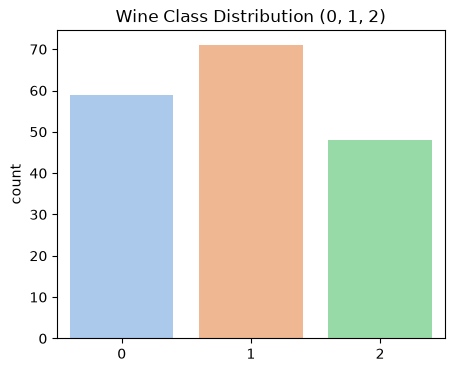

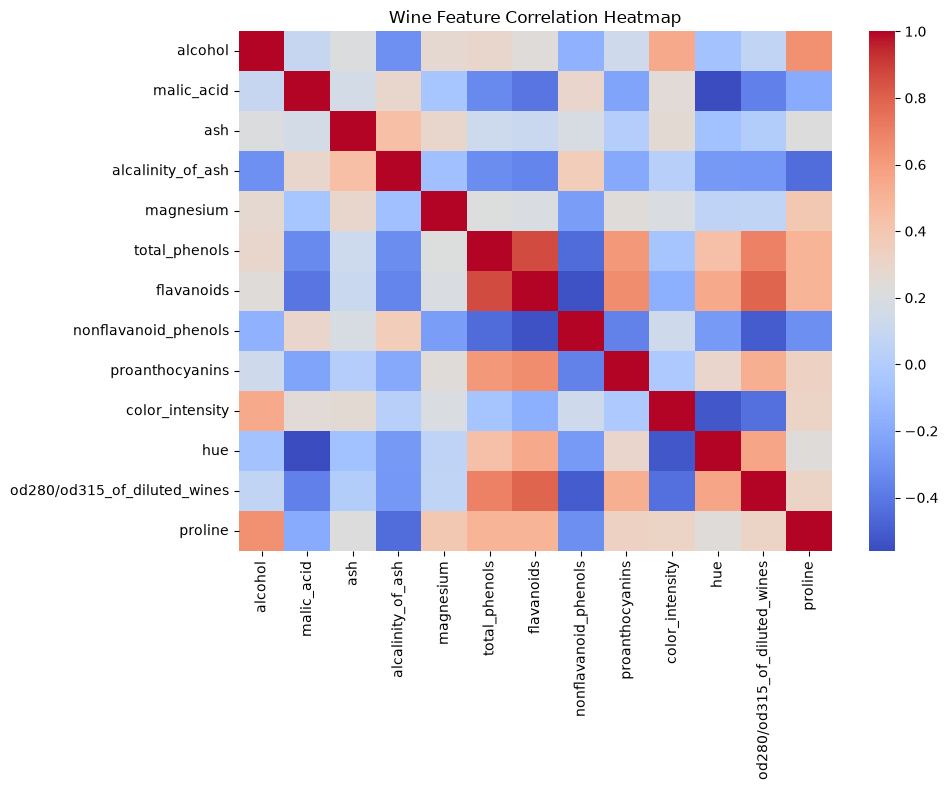

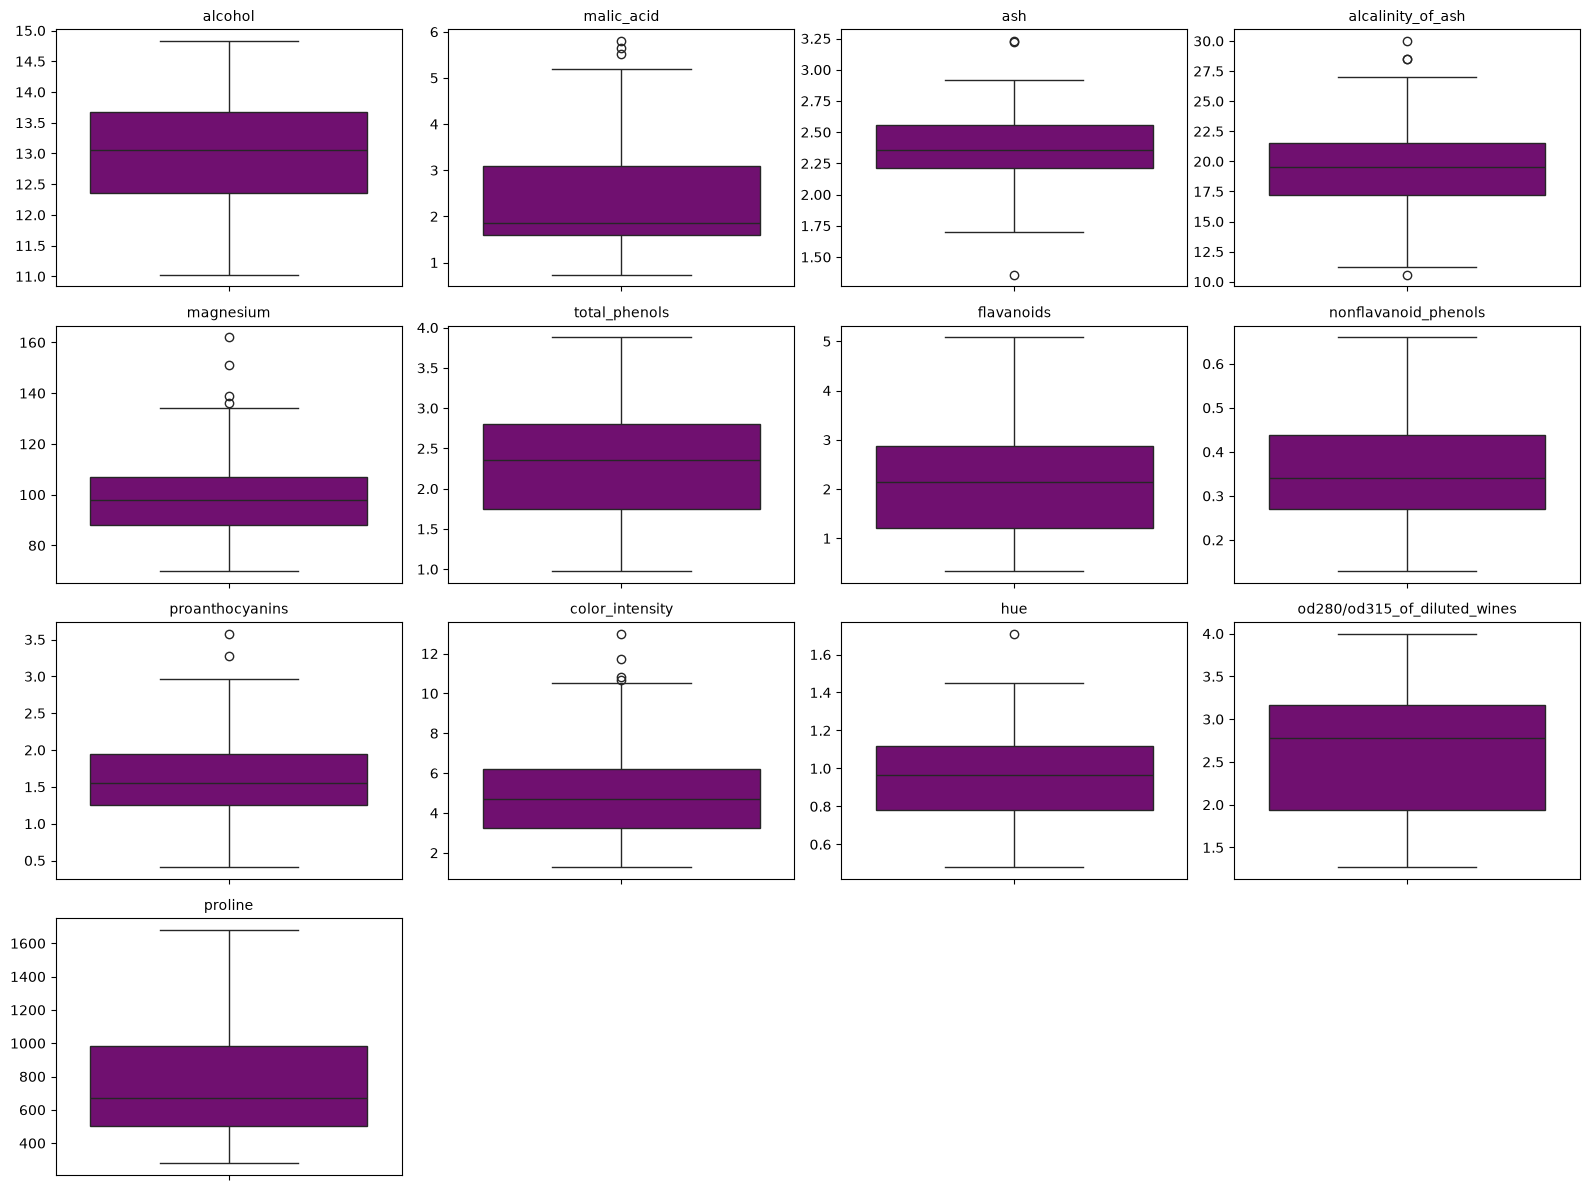

In [9]:
# ==========================================
# SECTION 1, 2 & 3: LOADING, QUALITY CHECKS & EDA (WINE)
# ==========================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_wine

# 1. Loading Dataset
raw_data = load_wine()

X = pd.DataFrame(raw_data.data, columns=raw_data.feature_names)
Y = raw_data.target
class_names = raw_data.target_names

print("=======================================================")
print(f"Wine Dataset Size: {X.shape[0]} rows, {X.shape[1]} columns")
print(pd.Series(Y).value_counts().rename(index={0: '0 (Class 0)', 1: '1 (Class 1)', 2: '2 (Class 2)'}))
print("=======================================================")
display(X.head())

# 2. Quality Checks
missing_values = X.isnull().sum().sum()
duplicate_rows = X.duplicated().sum()

print("--- 2.1 MISSING VALUES & DUPLICATES ---")
print(f"Total Missing Values: {missing_values}")
print(f"Duplicated Rows: {duplicate_rows}")

print("\n--- 2.3 DATA TYPES ---")
print(f"Numerical Features: {X.select_dtypes(include=['float64', 'int64']).shape[1]}")
print(f"Categorical Features: {X.select_dtypes(include=['object', 'category']).shape[1]}")

# 3.1 Descriptive Statistics (Ilk 5 Özellik)
stats = X.describe().T[['mean', '50%', 'min', 'max', 'std', '25%', '75%']]
stats = stats.rename(columns={'50%': 'median', '25%': 'Q1', '75%': 'Q3'})

print("\n--- 3.1 DESCRIPTIVE STATISTICS (FIRST 5 FEATURES) ---")
display(stats.head())

# 3.2 Top 3 Strongest Correlation Pairs (Pearson)
corr_matrix = X.corr().abs()
upper_tri = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
corr_unstacked = upper_tri.unstack().dropna().sort_values(ascending=False)

print("\n--- 3.2 TOP 3 STRONGEST CORRELATION PAIRS (PEARSON) ---")
for i, ((feat1, feat2), val) in enumerate(corr_unstacked.head(3).items(), 1):
    print(f"{i}. {feat1} <---> {feat2}: {val:.4f}")

# 3.2 Class Distribution Plot & Visualizations
plt.figure(figsize=(5, 4))
sns.countplot(x=Y, hue=Y, palette='pastel', legend=False)
plt.title("Wine Class Distribution (0, 1, 2)")
plt.show()

plt.figure(figsize=(10, 8))
sns.heatmap(X.corr(), cmap='coolwarm', annot=False)
plt.title("Wine Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

plt.figure(figsize=(16, 12))
for i, column in enumerate(X.columns):
    plt.subplot(4, 4, i + 1)
    sns.boxplot(y=X[column], color='purple')
    plt.title(column, fontsize=10)
    plt.ylabel('')
plt.tight_layout()
plt.show()

In [10]:
# ==========================================
# SECTION 4 & 5: SPLITTING AND SCALING (WINE)
# ==========================================
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

SEEDS = [42, 52, 62]

# Test kümesini SADECE BİR KERE (seed=42) ayırıyoruz (%20)
X_train_val_raw, X_test_raw, Y_train_val, Y_test = train_test_split(
    X, Y, test_size=0.20, random_state=42, stratify=Y
)

processed_datasets = {}
seed_42_scaler = None

for seed in SEEDS:
    X_train_raw, X_val_raw, Y_train, Y_val = train_test_split(
        X_train_val_raw, Y_train_val, test_size=0.125, random_state=seed, stratify=Y_train_val
    )
    
    scaler = StandardScaler()
    X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train_raw), columns=X.columns, index=X_train_raw.index)
    X_val_scaled = pd.DataFrame(scaler.transform(X_val_raw), columns=X.columns, index=X_val_raw.index)
    
    if seed == 42:
        X_test_scaled = pd.DataFrame(scaler.transform(X_test_raw), columns=X.columns, index=X_test_raw.index)
        seed_42_scaler = scaler
        
        print("--- 5.3 SCALING EVIDENCE (Seed 42) ---")
        print("BEFORE SCALING (First 5 Rows):")
        display(X_train_raw.head())
        print("\nAFTER SCALING (First 5 Rows):")
        display(X_train_scaled.head())
        
    processed_datasets[seed] = {
        'unscaled': {'X_train': X_train_raw, 'X_val': X_val_raw, 'Y_train': Y_train, 'Y_val': Y_val},
        'scaled':   {'X_train': X_train_scaled, 'X_val': X_val_scaled, 'Y_train': Y_train, 'Y_val': Y_val}
    }

print("\nVeri Bölme ve Ölçekleme Tamamlandı. Test seti boyutu:", X_test_raw.shape)

--- 5.3 SCALING EVIDENCE (Seed 42) ---
BEFORE SCALING (First 5 Rows):


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
163,12.96,3.45,2.35,18.5,106.0,1.39,0.70,0.40,0.94,5.28,0.68,1.75,675.0
148,13.32,3.24,2.38,21.5,92.0,1.93,0.76,0.45,1.25,8.42,0.55,1.62,650.0
116,11.82,1.47,1.99,20.8,86.0,1.98,1.60,0.30,1.53,1.95,0.95,3.33,495.0
122,12.42,4.43,2.73,26.5,102.0,2.20,2.13,0.43,1.71,2.08,0.92,3.12,365.0
115,11.03,1.51,2.20,21.5,85.0,2.46,2.17,0.52,2.01,1.90,1.71,2.87,407.0



AFTER SCALING (First 5 Rows):


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
163,-0.017514,1.089178,-0.040117,-0.308405,0.433224,-1.342505,-1.322275,0.352668,-1.117639,0.125837,-1.226754,-1.223646,-0.209375
148,0.439706,0.891779,0.072941,0.609409,-0.505699,-0.490993,-1.259892,0.769946,-0.571881,1.512255,-1.811372,-1.414652,-0.291400
116,-1.465379,-0.772006,-1.396814,0.395252,-0.908094,-0.412149,-0.386537,-0.481889,-0.078939,-1.344472,-0.012548,1.097809,-0.799954
122,-0.703345,2.010370,1.391951,2.139100,0.164961,-0.065237,0.164509,0.603035,0.237953,-1.287073,-0.147460,0.789262,-1.226483
115,-2.468723,-0.734407,-0.605407,0.609409,-0.975160,0.344750,0.206097,1.354136,0.766105,-1.366549,3.405216,0.421943,-1.088682



Veri Bölme ve Ölçekleme Tamamlandı. Test seti boyutu: (36, 13)


In [11]:
# ==========================================
# SECTION 4 & 5: SPLITTING AND SCALING (WINE)
# ==========================================
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

SEEDS = [42, 52, 62]

# 1. Freeze the test set once using seed 42 (20% test subset)
X_tr_val_raw, X_test_raw, Y_tr_val, Y_test = train_test_split(
    X, Y, test_size=0.20, random_state=42, stratify=Y
)

processed_datasets, split_summary, test_indices = {}, [], []

# 2. Repeated train/validation splitting, summary data collection, and scaling across 3 seeds
for seed in SEEDS:
    X_tr_raw, X_v_raw, Y_tr, Y_v = train_test_split(
        X_tr_val_raw, Y_tr_val, test_size=0.125, random_state=seed, stratify=Y_tr_val
    )
    
    # 4.2 Record split summary statistics (Wine: Class 0, Class 1, Class 2)
    for name, x_sub, y_sub in [('Train', X_tr_raw, Y_tr), ('Validation', X_v_raw, Y_v), ('Test', X_test_raw, Y_test)]:
        row = {'Seed': seed, 'Subset': name, 'Rows': len(x_sub), '%': round(len(x_sub)/len(X)*100, 1)}
        row.update({f'Class {k}': v for k, v in sorted(pd.Series(y_sub).value_counts().items())})
        split_summary.append(row)
        
    test_indices.append(X_test_raw.index.to_numpy())
    
    # 5.3 Feature scaling (scaler fitted exclusively on training data)
    scaler = StandardScaler()
    X_tr_sc = pd.DataFrame(scaler.fit_transform(X_tr_raw), columns=X.columns, index=X_tr_raw.index)
    X_v_sc = pd.DataFrame(scaler.transform(X_v_raw), columns=X.columns, index=X_v_raw.index)
    
    if seed == 42:
        X_test_scaled = pd.DataFrame(scaler.transform(X_test_raw), columns=X.columns, index=X_test_raw.index)
        seed_42_scaler = scaler
        
        print("--- 5.3 SCALING EVIDENCE (Seed 42) ---")
        print("BEFORE SCALING (First 5 Rows):")
        display(X_tr_raw.head())
        print("\nAFTER SCALING (First 5 Rows):")
        display(X_tr_sc.head())
         
    processed_datasets[seed] = {
        'unscaled': {'X_train': X_tr_raw, 'X_val': X_v_raw, 'Y_train': Y_tr, 'Y_val': Y_v},
        'scaled':   {'X_train': X_tr_sc,  'X_val': X_v_sc,  'Y_train': Y_tr, 'Y_val': Y_v}
    }

# 3. Display Section 4.2 outputs and perform verification check
print("\n--- 4.2 SPLIT SUMMARY TABLE (9 Rows) ---")
display(pd.DataFrame(split_summary))

is_identical = np.array_equal(test_indices[0], test_indices[1]) and np.array_equal(test_indices[1], test_indices[2])
print(f"\n[VERIFICATION] Test indices identical across seeds: {is_identical}")
print(f"Test set shape: {X_test_raw.shape}")

--- 5.3 SCALING EVIDENCE (Seed 42) ---
BEFORE SCALING (First 5 Rows):


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
163,12.96,3.45,2.35,18.5,106.0,1.39,0.70,0.40,0.94,5.28,0.68,1.75,675.0
148,13.32,3.24,2.38,21.5,92.0,1.93,0.76,0.45,1.25,8.42,0.55,1.62,650.0
116,11.82,1.47,1.99,20.8,86.0,1.98,1.60,0.30,1.53,1.95,0.95,3.33,495.0
122,12.42,4.43,2.73,26.5,102.0,2.20,2.13,0.43,1.71,2.08,0.92,3.12,365.0
115,11.03,1.51,2.20,21.5,85.0,2.46,2.17,0.52,2.01,1.90,1.71,2.87,407.0



AFTER SCALING (First 5 Rows):


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
163,-0.017514,1.089178,-0.040117,-0.308405,0.433224,-1.342505,-1.322275,0.352668,-1.117639,0.125837,-1.226754,-1.223646,-0.209375
148,0.439706,0.891779,0.072941,0.609409,-0.505699,-0.490993,-1.259892,0.769946,-0.571881,1.512255,-1.811372,-1.414652,-0.291400
116,-1.465379,-0.772006,-1.396814,0.395252,-0.908094,-0.412149,-0.386537,-0.481889,-0.078939,-1.344472,-0.012548,1.097809,-0.799954
122,-0.703345,2.010370,1.391951,2.139100,0.164961,-0.065237,0.164509,0.603035,0.237953,-1.287073,-0.147460,0.789262,-1.226483
115,-2.468723,-0.734407,-0.605407,0.609409,-0.975160,0.344750,0.206097,1.354136,0.766105,-1.366549,3.405216,0.421943,-1.088682



--- 4.2 SPLIT SUMMARY TABLE (9 Rows) ---


,Seed,Subset,Rows,%,Class 0,Class 1,Class 2
0,42,Train,124,69.7,41,50,33
1,42,Validation,18,10.1,6,7,5
2,42,Test,36,20.2,12,14,10
3,52,Train,124,69.7,41,50,33
4,52,Validation,18,10.1,6,7,5
5,52,Test,36,20.2,12,14,10
6,62,Train,124,69.7,41,50,33
7,62,Validation,18,10.1,6,7,5
8,62,Test,36,20.2,12,14,10



[VERIFICATION] Test indices identical across seeds: True
Test set shape: (36, 13)


In [12]:
# ==========================================
# SECTION 7 & 8.1: CLASSIFIER RUNS (WINE)
# ==========================================
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

classifier_runs = []
fitted_models_seed42 = {}

dt_depths = [2, 3, 5, 10, None]
knn_ks = [1, 3, 5, 7, 11]
representations = ['unscaled', 'scaled']

for seed in SEEDS:
    for rep in representations:
        X_tr = processed_datasets[seed][rep]['X_train']
        Y_tr = processed_datasets[seed][rep]['Y_train']
        X_va = processed_datasets[seed][rep]['X_val']
        Y_va = processed_datasets[seed][rep]['Y_val']
        
        # 1. Decision Tree (5 Derinlik)
        for depth in dt_depths:
            run_id = f"wine_dt_{rep}_depth{depth}_s{seed}"
            model = DecisionTreeClassifier(max_depth=depth, random_state=seed)
            model.fit(X_tr, Y_tr)
            
            tr_preds = model.predict(X_tr)
            va_preds = model.predict(X_va)
            va_probs = model.predict_proba(X_va)
            
            # WINE ROC-AUC: multi_class='ovr' ve average='macro' (Hocanın kuralı)
            classifier_runs.append({
                'run_id': run_id, 'dataset': 'wine', 'seed': seed, 'algorithm': 'DecisionTree',
                'representation': rep, 'parameter': str(depth),
                'train_acc': accuracy_score(Y_tr, tr_preds),
                'train_macro_f1': f1_score(Y_tr, tr_preds, average='macro'),
                'val_acc': accuracy_score(Y_va, va_preds),
                'val_macro_prec': precision_score(Y_va, va_preds, average='macro', zero_division=0),
                'val_macro_rec': recall_score(Y_va, va_preds, average='macro', zero_division=0),
                'val_macro_f1': f1_score(Y_va, va_preds, average='macro', zero_division=0),
                'val_roc_auc': roc_auc_score(Y_va, va_probs, multi_class='ovr', average='macro')
            })
            if seed == 42: fitted_models_seed42[run_id] = model
            
        # 2. KNN (5 K değeri)
        for k in knn_ks:
            run_id = f"wine_knn_{rep}_k{k}_s{seed}"
            model = KNeighborsClassifier(n_neighbors=k)
            model.fit(X_tr, Y_tr)
            
            tr_preds = model.predict(X_tr)
            va_preds = model.predict(X_va)
            va_probs = model.predict_proba(X_va)
            
            classifier_runs.append({
                'run_id': run_id, 'dataset': 'wine', 'seed': seed, 'algorithm': 'KNN',
                'representation': rep, 'parameter': str(k),
                'train_acc': accuracy_score(Y_tr, tr_preds),
                'train_macro_f1': f1_score(Y_tr, tr_preds, average='macro'),
                'val_acc': accuracy_score(Y_va, va_preds),
                'val_macro_prec': precision_score(Y_va, va_preds, average='macro', zero_division=0),
                'val_macro_rec': recall_score(Y_va, va_preds, average='macro', zero_division=0),
                'val_macro_f1': f1_score(Y_va, va_preds, average='macro', zero_division=0),
                'val_roc_auc': roc_auc_score(Y_va, va_probs, multi_class='ovr', average='macro')
            })
            if seed == 42: fitted_models_seed42[run_id] = model
            
        # 3. Gaussian Naive Bayes
        run_id = f"wine_nb_{rep}_default_s{seed}"
        model = GaussianNB()
        model.fit(X_tr, Y_tr)
        
        tr_preds = model.predict(X_tr)
        va_preds = model.predict(X_va)
        va_probs = model.predict_proba(X_va)
        
        classifier_runs.append({
            'run_id': run_id, 'dataset': 'wine', 'seed': seed, 'algorithm': 'GaussianNB',
            'representation': rep, 'parameter': 'default',
            'train_acc': accuracy_score(Y_tr, tr_preds),
            'train_macro_f1': f1_score(Y_tr, tr_preds, average='macro'),
            'val_acc': accuracy_score(Y_va, va_preds),
            'val_macro_prec': precision_score(Y_va, va_preds, average='macro', zero_division=0),
            'val_macro_rec': recall_score(Y_va, va_preds, average='macro', zero_division=0),
            'val_macro_f1': f1_score(Y_va, va_preds, average='macro', zero_division=0),
            'val_roc_auc': roc_auc_score(Y_va, va_probs, multi_class='ovr', average='macro')
        })
        if seed == 42: fitted_models_seed42[run_id] = model

df_wine_runs = pd.DataFrame(classifier_runs)
print(f"Wine Classifier Çalıştırmaları Tamamlandı: {len(df_wine_runs)}/66")

Wine Classifier Çalıştırmaları Tamamlandı: 66/66


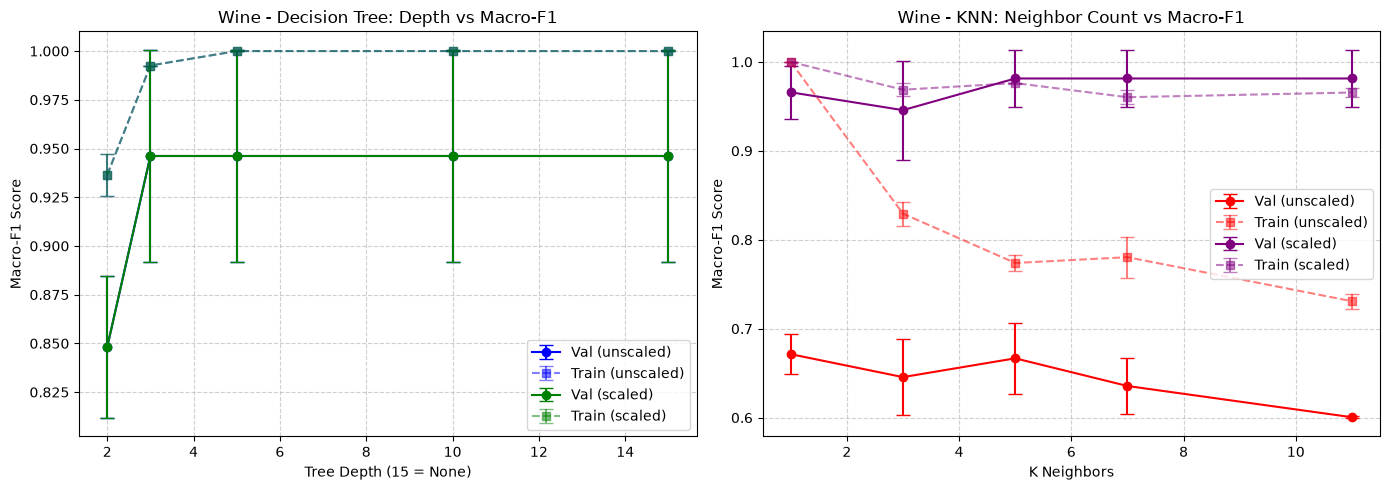

In [13]:
# ==========================================
# SECTION 8.2: WINE ERROR-BAR PLOTS
# ==========================================
import matplotlib.pyplot as plt

df_wine_summary = df_wine_runs.groupby(['dataset', 'algorithm', 'representation', 'parameter']).agg(
    mean_train_macro_f1=('train_macro_f1', 'mean'),
    std_train_macro_f1=('train_macro_f1', 'std'),
    mean_val_macro_f1=('val_macro_f1', 'mean'),
    std_val_macro_f1=('val_macro_f1', 'std'),
    mean_val_acc=('val_acc', 'mean')
).reset_index().sort_values(by=['mean_val_macro_f1', 'mean_val_acc'], ascending=[False, False])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Decision Tree Error Bar Plot
dt_df = df_wine_summary[df_wine_summary['algorithm'] == 'DecisionTree'].copy()
dt_df['x_param'] = dt_df['parameter'].apply(lambda x: 15 if x == 'None' else int(x))
dt_df = dt_df.sort_values(by='x_param')

for rep, color in zip(['unscaled', 'scaled'], ['blue', 'green']):
    sub = dt_df[dt_df['representation'] == rep]
    axes[0].errorbar(sub['x_param'], sub['mean_val_macro_f1'], yerr=sub['std_val_macro_f1'], 
                     marker='o', capsize=5, label=f'Val ({rep})', color=color)
    axes[0].errorbar(sub['x_param'], sub['mean_train_macro_f1'], yerr=sub['std_train_macro_f1'], 
                     marker='s', capsize=5, linestyle='--', label=f'Train ({rep})', color=color, alpha=0.5)

axes[0].set_title("Wine - Decision Tree: Depth vs Macro-F1")
axes[0].set_xlabel("Tree Depth (15 = None)")
axes[0].set_ylabel("Macro-F1 Score")
axes[0].legend(); axes[0].grid(True, linestyle='--', alpha=0.6)

# KNN Error Bar Plot
knn_df = df_wine_summary[df_wine_summary['algorithm'] == 'KNN'].copy()
knn_df['x_param'] = knn_df['parameter'].astype(int)
knn_df = knn_df.sort_values(by='x_param')

for rep, color in zip(['unscaled', 'scaled'], ['red', 'purple']):
    sub = knn_df[knn_df['representation'] == rep]
    axes[1].errorbar(sub['x_param'], sub['mean_val_macro_f1'], yerr=sub['std_val_macro_f1'], 
                     marker='o', capsize=5, label=f'Val ({rep})', color=color)
    axes[1].errorbar(sub['x_param'], sub['mean_train_macro_f1'], yerr=sub['std_train_macro_f1'], 
                     marker='s', capsize=5, linestyle='--', label=f'Train ({rep})', color=color, alpha=0.5)

axes[1].set_title("Wine - KNN: Neighbor Count vs Macro-F1")
axes[1].set_xlabel("K Neighbors")
axes[1].set_ylabel("Macro-F1 Score")
axes[1].legend(); axes[1].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

--- 9.1 WINE CLASSIFICATION REPORT (TEST SET) ---
              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        12
     class_1       1.00      1.00      1.00        14
     class_2       1.00      1.00      1.00        10

    accuracy                           1.00        36
   macro avg       1.00      1.00      1.00        36
weighted avg       1.00      1.00      1.00        36



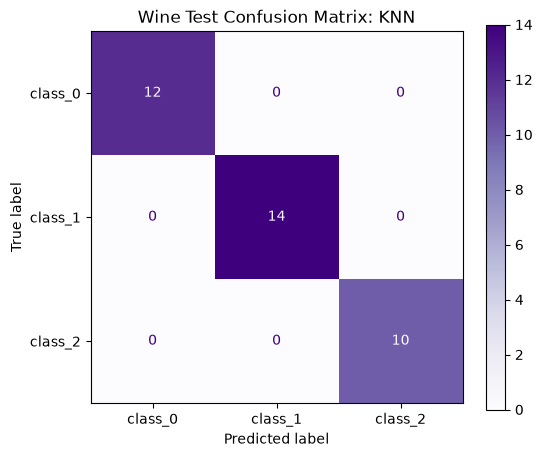

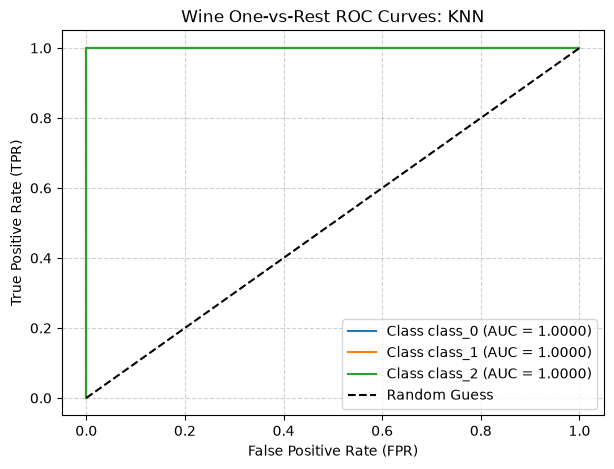

In [14]:
# ==========================================
# SECTION 9: TEST EVALUATION, 3x3 CM & MULTI-CLASS ROC (WINE)
# ==========================================
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, roc_curve, auc
from sklearn.preprocessing import label_binarize

best_config = df_wine_summary.iloc[0]
best_run_id = df_wine_runs[
    (df_wine_runs['algorithm'] == best_config['algorithm']) &
    (df_wine_runs['representation'] == best_config['representation']) &
    (df_wine_runs['parameter'] == best_config['parameter']) &
    (df_wine_runs['seed'] == 42)
]['run_id'].values[0]

best_model = fitted_models_seed42[best_run_id]
X_te = X_test_scaled if best_config['representation'] == 'scaled' else X_test_raw

test_preds = best_model.predict(X_te)
test_probs = best_model.predict_proba(X_te)

print("--- 9.1 WINE CLASSIFICATION REPORT (TEST SET) ---")
print(classification_report(Y_test, test_preds, target_names=class_names))

# 3x3 Confusion Matrix
fig, ax = plt.subplots(figsize=(6, 5))
cm = confusion_matrix(Y_test, test_preds)
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(ax=ax, cmap='Purples')
ax.set_title(f"Wine Test Confusion Matrix: {best_config['algorithm']}")
plt.show()

# Multi-Class ROC Curve (Section 9.3)
y_test_bin = label_binarize(Y_test, classes=[0, 1, 2])
plt.figure(figsize=(7, 5))

for i in range(3):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], test_probs[:, i])
    roc_auc_val = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f"Class {class_names[i]} (AUC = {roc_auc_val:.4f})")

plt.plot([0, 1], [0, 1], 'k--', label='Random Guess')
plt.xlabel("False Positive Rate (FPR)")
plt.ylabel("True Positive Rate (TPR)")
plt.title(f"Wine One-vs-Rest ROC Curves: {best_config['algorithm']}")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

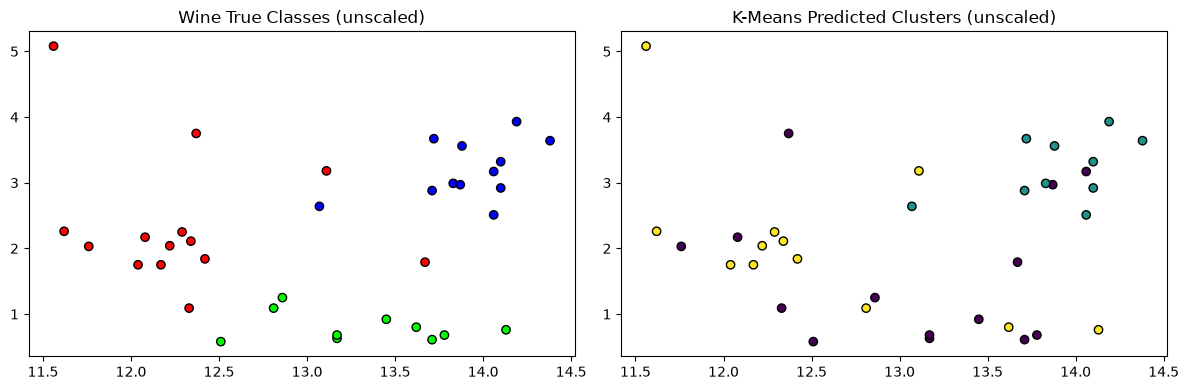

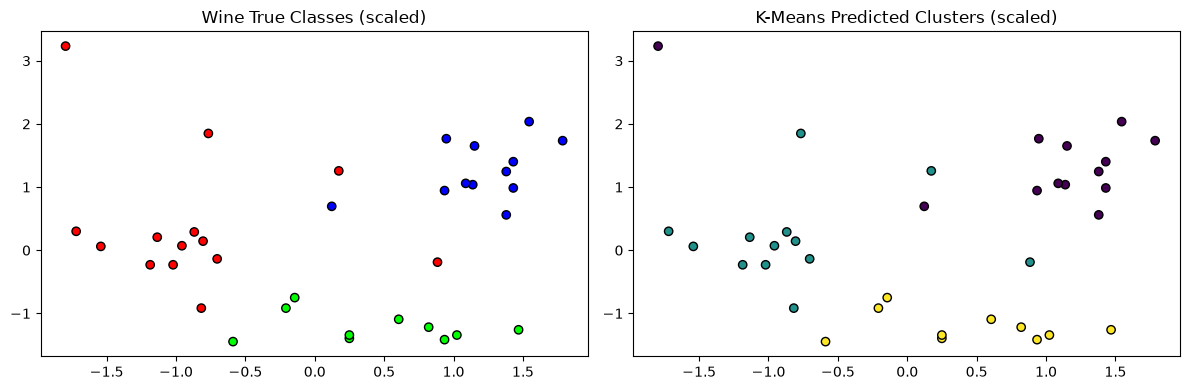

In [17]:
# ==========================================
# SECTION 10: K-MEANS CLUSTERING & VISUALIZATION (WINE: K=3)
# ==========================================
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score

kmeans_runs = []
kmeans_models_seed42 = {}

for seed in SEEDS:
    for rep in representations:
        X_tr = processed_datasets[seed][rep]['X_train']
        X_va = processed_datasets[seed][rep]['X_val']
        Y_va = processed_datasets[seed][rep]['Y_val']
        
        km = KMeans(n_clusters=3, random_state=seed, n_init=10)
        km.fit(X_tr)
        val_clusters = km.predict(X_va)
        
        kmeans_runs.append({
            'dataset': 'wine', 'seed': seed, 'representation': rep,
            'inertia': km.inertia_,
            'val_ari': adjusted_rand_score(Y_va, val_clusters),
            'val_silhouette': silhouette_score(X_va, val_clusters)
        })
        if seed == 42: kmeans_models_seed42[rep] = km

df_wine_kmeans_runs = pd.DataFrame(kmeans_runs)

# K-Means Visualisation (alcohol vs flavanoids)
f1, f2 = 'alcohol', 'flavanoids'
for rep in representations:
    X_te = X_test_scaled if rep == 'scaled' else X_test_raw
    test_clusters = kmeans_models_seed42[rep].predict(X_te)
    
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].scatter(X_te[f1], X_te[f2], c=Y_test, cmap='brg', edgecolor='k')
    axes[0].set_title(f"Wine True Classes ({rep})")
    
    axes[1].scatter(X_te[f1], X_te[f2], c=test_clusters, cmap='viridis', edgecolor='k')
    axes[1].set_title(f"K-Means Predicted Clusters ({rep})")
    plt.tight_layout(); plt.show()

In [19]:
# ==========================================
# SECTION 12.2: EXPORT CSV FILES (WINE)
# ==========================================
import pandas as pd
import numpy as np
import os
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, adjusted_rand_score, silhouette_score

DATASET_NAME = 'wine'

# --- 1. CREATE WINE CLASSIFIER TEST TABLE ---
df_classifier_test = pd.DataFrame([{
    'dataset': 'wine',
    'selected_configuration': f"{best_config['algorithm']}_{best_config['representation']}_{best_config['parameter']}",
    'eval_seed': 42,
    'mean_val_macro_f1': best_config['mean_val_macro_f1'],
    'std_val_macro_f1': best_config['std_val_macro_f1'],
    'test_acc': accuracy_score(Y_test, test_preds),
    'test_macro_prec': precision_score(Y_test, test_preds, average='macro', zero_division=0),
    'test_macro_rec': recall_score(Y_test, test_preds, average='macro', zero_division=0),
    'test_macro_f1': f1_score(Y_test, test_preds, average='macro', zero_division=0),
    'test_roc_auc': roc_auc_score(Y_test, test_probs, multi_class='ovr', average='macro')
}])

# --- 2. CREATE WINE K-MEANS SUMMARY TABLE ---
df_km_sum_wine = df_wine_kmeans_runs.groupby(['dataset', 'representation']).agg(
    mean_val_ari=('val_ari', 'mean'), 
    std_val_ari=('val_ari', 'std'), 
    valid_score_count=('val_silhouette', 'count')
).reset_index()

# --- 3. CREATE WINE K-MEANS TEST TABLE ---
kmeans_test_wine = []
for rep in representations:
    X_te = X_test_scaled if rep == 'scaled' else X_test_raw
    km_model = kmeans_models_seed42[rep]
    test_clusters = km_model.predict(X_te)
    sil_score_test = silhouette_score(X_te, test_clusters) if len(np.unique(test_clusters)) > 1 else np.nan
    kmeans_test_wine.append({
        'dataset': 'wine', 'representation': rep, 'eval_seed': 42,
        'cluster_0_count': sum(test_clusters == 0), 'cluster_1_count': sum(test_clusters == 1),
        'test_ari': adjusted_rand_score(Y_test, test_clusters), 'test_silhouette': sil_score_test
    })
df_km_test_wine = pd.DataFrame(kmeans_test_wine)

# --- 4. FILE MAPPING (WINE SPECIFIC) ---
csv_mapping = {
    'classifier_runs.csv': df_wine_runs,
    'classifier_summary.csv': df_wine_summary,
    'classifier_test.csv': df_classifier_test,
    'kmeans_runs.csv': df_wine_kmeans_runs,
    'kmeans_summary.csv': df_km_sum_wine,
    'kmeans_test.csv': df_km_test_wine
}

print(f"--- SAVING {DATASET_NAME.upper()} RESULTS ---")

# --- 5. SMART MERGE AND SAVE ---
for filename, df_new in csv_mapping.items():
    if os.path.exists(filename):
        # Read existing file, drop old wine records to prevent duplicates, append new ones
        df_existing = pd.read_csv(filename)
        if 'dataset' in df_existing.columns:
            df_existing = df_existing[df_existing['dataset'] != DATASET_NAME]
        df_combined = pd.concat([df_existing, df_new], ignore_index=True)
        df_combined.to_csv(filename, index=False)
        print(f"UPDATED: {filename} (Total rows: {len(df_combined)})")
    else:
        # Create file if it doesn't exist
        df_new.to_csv(filename, index=False)
        print(f"CREATED: {filename} (Total rows: {len(df_new)})")

--- SAVING WINE RESULTS ---
UPDATED: classifier_runs.csv (Total rows: 132)
UPDATED: classifier_summary.csv (Total rows: 44)
UPDATED: classifier_test.csv (Total rows: 2)
UPDATED: kmeans_runs.csv (Total rows: 12)
UPDATED: kmeans_summary.csv (Total rows: 4)
UPDATED: kmeans_test.csv (Total rows: 4)
